In [55]:
import os
import pandas as pd
from pathlib import Path
data_folder = Path("data/train.csv")
data_path = os.path.join(os.getcwd(), data_folder)

print(data_path)

# # submission data format
# df = pd.read_parquet(data_path)
# df.head()

df = pd.read_csv(data_path)
df.head()

c:\Users\ps302\OneDrive\Desktop\Name_that_LLM\data\train.csv


,id,prompt_id,text,model
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",qwen3.8-max
1,0041ac86ee93,p073,Data science communities matter because they a...,claude-sonnet-5
2,005a19083eae,p120,"In the final twilight of time, the last embers...",gemini-3.6-flash
3,009319596f10,p073,Data science communities matter because they t...,gpt-5.6-terra
4,00d3e8c92596,p097,"Deep inside each ear, three tiny loops of bone...",glm-5.3-flash


In [56]:
# %pip install pyarrow
# !pip install nltk
# !pip install wordcloud

### Data Cleaning



In [57]:
df.isnull().sum()

id           0
prompt_id    0
text         0
model        0
dtype: int64

In [58]:
df.duplicated().sum()

np.int64(0)

In [59]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2699 entries, 0 to 2698
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         2699 non-null   object
 1   prompt_id  2699 non-null   object
 2   text       2699 non-null   object
 3   model      2699 non-null   object
dtypes: object(4)
memory usage: 84.5+ KB


In [60]:
df.head(5)

,id,prompt_id,text,model
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",qwen3.8-max
1,0041ac86ee93,p073,Data science communities matter because they a...,claude-sonnet-5
2,005a19083eae,p120,"In the final twilight of time, the last embers...",gemini-3.6-flash
3,009319596f10,p073,Data science communities matter because they t...,gpt-5.6-terra
4,00d3e8c92596,p097,"Deep inside each ear, three tiny loops of bone...",glm-5.3-flash


In [61]:
# Applying label encoder
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df["model"] = le.fit_transform(df["model"])
df.head(5)

,id,prompt_id,text,model
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",17
1,0041ac86ee93,p073,Data science communities matter because they a...,4
2,005a19083eae,p120,"In the final twilight of time, the last embers...",6
3,009319596f10,p073,Data science communities matter because they t...,14
4,00d3e8c92596,p097,"Deep inside each ear, three tiny loops of bone...",10


In [62]:
print(le.classes_)
print(le.transform(le.classes_))

['claude-fable-5' 'claude-opus-4-6' 'claude-opus-4-8' 'claude-opus-5'
 'claude-sonnet-5' 'gemini-3.1-pro-preview' 'gemini-3.6-flash'
 'gemini-3.7-flash' 'gemini-3.8-flash' 'glm-5.3' 'glm-5.3-flash' 'gpt-5.5'
 'gpt-5.6-luna' 'gpt-5.6-sol' 'gpt-5.6-terra' 'gpt-6-astra' 'kimi-k3'
 'qwen3.8-max']
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17]


In [63]:
mapping = dict(zip(le.classes_, le.transform(le.classes_)))
print(mapping)

{'claude-fable-5': np.int64(0), 'claude-opus-4-6': np.int64(1), 'claude-opus-4-8': np.int64(2), 'claude-opus-5': np.int64(3), 'claude-sonnet-5': np.int64(4), 'gemini-3.1-pro-preview': np.int64(5), 'gemini-3.6-flash': np.int64(6), 'gemini-3.7-flash': np.int64(7), 'gemini-3.8-flash': np.int64(8), 'glm-5.3': np.int64(9), 'glm-5.3-flash': np.int64(10), 'gpt-5.5': np.int64(11), 'gpt-5.6-luna': np.int64(12), 'gpt-5.6-sol': np.int64(13), 'gpt-5.6-terra': np.int64(14), 'gpt-6-astra': np.int64(15), 'kimi-k3': np.int64(16), 'qwen3.8-max': np.int64(17)}


### EDA

<Axes: ylabel='count'>

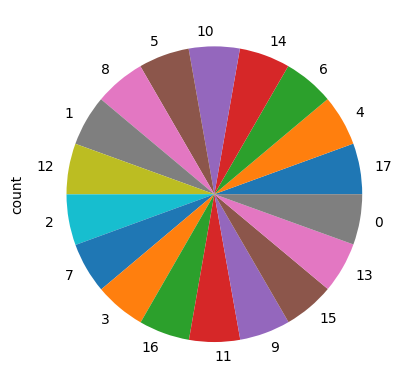

In [64]:
df["model"].value_counts().plot.pie()

<function matplotlib.pyplot.show(close=None, block=None)>

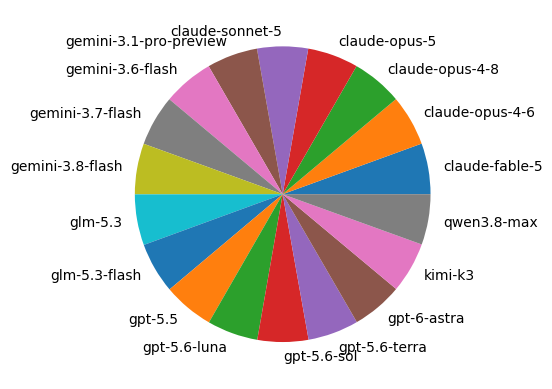

In [65]:
import matplotlib.pyplot as plt 
plt.pie(df["model"].value_counts(), labels=le.classes_, )
plt.show

In [66]:
df.head()

,id,prompt_id,text,model
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",17
1,0041ac86ee93,p073,Data science communities matter because they a...,4
2,005a19083eae,p120,"In the final twilight of time, the last embers...",6
3,009319596f10,p073,Data science communities matter because they t...,14
4,00d3e8c92596,p097,"Deep inside each ear, three tiny loops of bone...",10


In [67]:
text = df.iloc[0]["text"]
print(f"Text: {text}")
print(f"Split Text: {text.split()}")

Text: When a language dies, a particular astronomy dims: not only names for stars, but whole grammars of attention that taught speakers how to read the night. Some tongues map the sky by kinship, binding the Milky Way to ancestors, rivers, or the migration paths of birds; others encode lunar phases as verbs, so time is not a line but a recurring breath. A word can carry the exact color of dawn on snow, the etiquette of speaking to thunder, or the mathematics woven into knot calendars and oral star charts. With extinction, those relations collapse into silence. No dictionary can resurrect the sky those speakers inhabited, nor the quiet ethics it taught. We lose metaphors that made the universe intimate, ethical, and alive, cosmologies in which darkness is a listener, comets are warnings carried by relatives, and constellations are not fixed pictures but seasonal responsibilities. The loss is not merely lexical; it is the erasure of possible human answers to wonder. What remains is a sma

In [68]:
print(f"Before len (str.split): {len(text.split())}")
y = []
for i in text.split():
    if i.isalnum():
        y.append(i)
    else:
        y.append(i)
print(f"After Len (str.split): {len(y)}")

Before len (str.split): 192
After Len (str.split): 192


In [69]:
import nltk
nltk.download("punkt")
from nltk.tokenize import word_tokenize, sent_tokenize

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\ps302\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\ps302\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [70]:
splits = word_tokenize(text)
print(splits)
print(f"Length of text (word_tokenise): {len(splits)}")

['When', 'a', 'language', 'dies', ',', 'a', 'particular', 'astronomy', 'dims', ':', 'not', 'only', 'names', 'for', 'stars', ',', 'but', 'whole', 'grammars', 'of', 'attention', 'that', 'taught', 'speakers', 'how', 'to', 'read', 'the', 'night', '.', 'Some', 'tongues', 'map', 'the', 'sky', 'by', 'kinship', ',', 'binding', 'the', 'Milky', 'Way', 'to', 'ancestors', ',', 'rivers', ',', 'or', 'the', 'migration', 'paths', 'of', 'birds', ';', 'others', 'encode', 'lunar', 'phases', 'as', 'verbs', ',', 'so', 'time', 'is', 'not', 'a', 'line', 'but', 'a', 'recurring', 'breath', '.', 'A', 'word', 'can', 'carry', 'the', 'exact', 'color', 'of', 'dawn', 'on', 'snow', ',', 'the', 'etiquette', 'of', 'speaking', 'to', 'thunder', ',', 'or', 'the', 'mathematics', 'woven', 'into', 'knot', 'calendars', 'and', 'oral', 'star', 'charts', '.', 'With', 'extinction', ',', 'those', 'relations', 'collapse', 'into', 'silence', '.', 'No', 'dictionary', 'can', 'resurrect', 'the', 'sky', 'those', 'speakers', 'inhabited',

In [71]:
df["num_chars"] = df["text"].apply(len)
df.head()

,id,prompt_id,text,model,num_chars
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",17,1143
1,0041ac86ee93,p073,Data science communities matter because they a...,4,518
2,005a19083eae,p120,"In the final twilight of time, the last embers...",6,474
3,009319596f10,p073,Data science communities matter because they t...,14,1724
4,00d3e8c92596,p097,"Deep inside each ear, three tiny loops of bone...",10,541


In [72]:
df["num_words"] = df["text"].apply(lambda x: len(word_tokenize(x)))
df.head()

,id,prompt_id,text,model,num_chars,num_words
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",17,1143,222
1,0041ac86ee93,p073,Data science communities matter because they a...,4,518,74
2,005a19083eae,p120,"In the final twilight of time, the last embers...",6,474,89
3,009319596f10,p073,Data science communities matter because they t...,14,1724,263
4,00d3e8c92596,p097,"Deep inside each ear, three tiny loops of bone...",10,541,114


In [73]:
df["num_sents"] = df["text"].apply(lambda x: len(sent_tokenize(x)))
df.head()

,id,prompt_id,text,model,num_chars,num_words,num_sents
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",17,1143,222,8
1,0041ac86ee93,p073,Data science communities matter because they a...,4,518,74,4
2,005a19083eae,p120,"In the final twilight of time, the last embers...",6,474,89,4
3,009319596f10,p073,Data science communities matter because they t...,14,1724,263,9
4,00d3e8c92596,p097,"Deep inside each ear, three tiny loops of bone...",10,541,114,4


In [74]:
df[["num_chars", "num_words", "num_sents"]].describe()

,num_chars,num_words,num_sents
count,2699.000000,2699.000000,2699.000000
mean,755.289366,133.846239,4.859207
std,377.371075,66.641015,2.170844
min,230.000000,42.000000,1.000000
25%,429.000000,77.000000,3.000000
50%,670.000000,119.000000,5.000000
75%,1027.000000,182.000000,6.000000
max,1900.000000,313.000000,14.000000


In [75]:
df[df["model"] == 0][["num_chars", "num_words", "num_sents"]].describe()

,num_chars,num_words,num_sents
count,149.000000,149.000000,149.000000
mean,731.020134,133.161074,4.724832
std,371.800485,67.474026,1.906103
min,259.000000,48.000000,1.000000
25%,429.000000,76.000000,3.000000
50%,646.000000,120.000000,5.000000
75%,940.000000,171.000000,6.000000
max,1875.000000,300.000000,11.000000


In [76]:
total_model = len(df["model"].unique())
print(total_model)

18


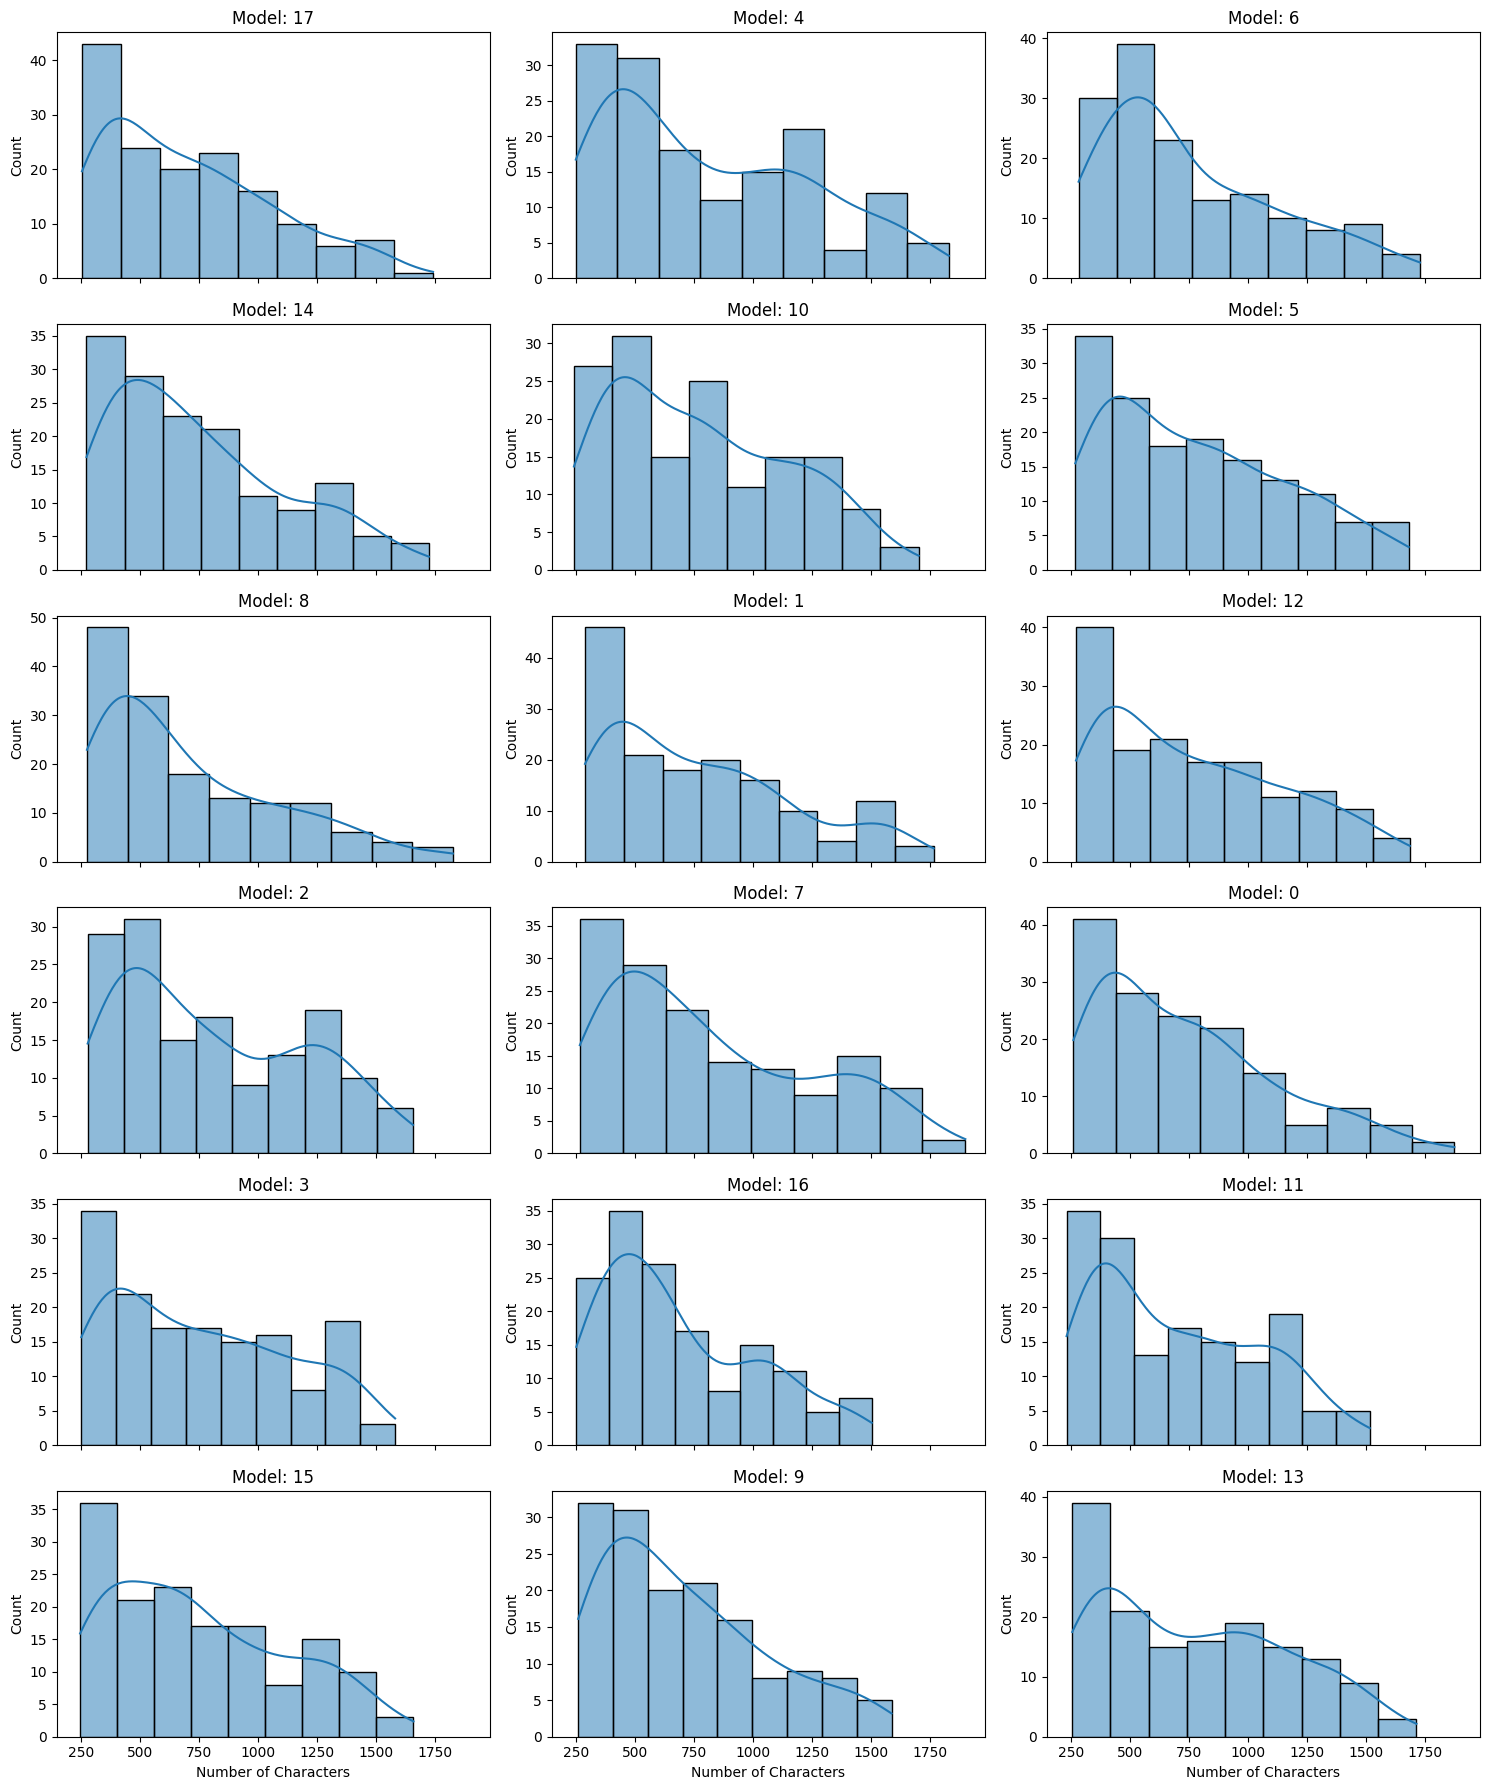

In [77]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

# Get unique models (works whether models are labeled 0-17 or by model names)
models = df["model"].unique()
total_models = len(models)  # 18

ncols = 3
nrows = math.ceil(total_models / ncols)  # 6 rows

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(15, 18), sharex=True)
axes = axes.flatten()  # Flatten to easily iterate 1D

for i, model in enumerate(models):
    subset = df[df["model"] == model]["num_chars"]
    sns.histplot(subset, ax=axes[i], kde=True)
    axes[i].set_title(f"Model: {model}")
    axes[i].set_xlabel("Number of Characters")
    axes[i].set_ylabel("Count")

# Hide any empty subplots if total_models < nrows * ncols
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


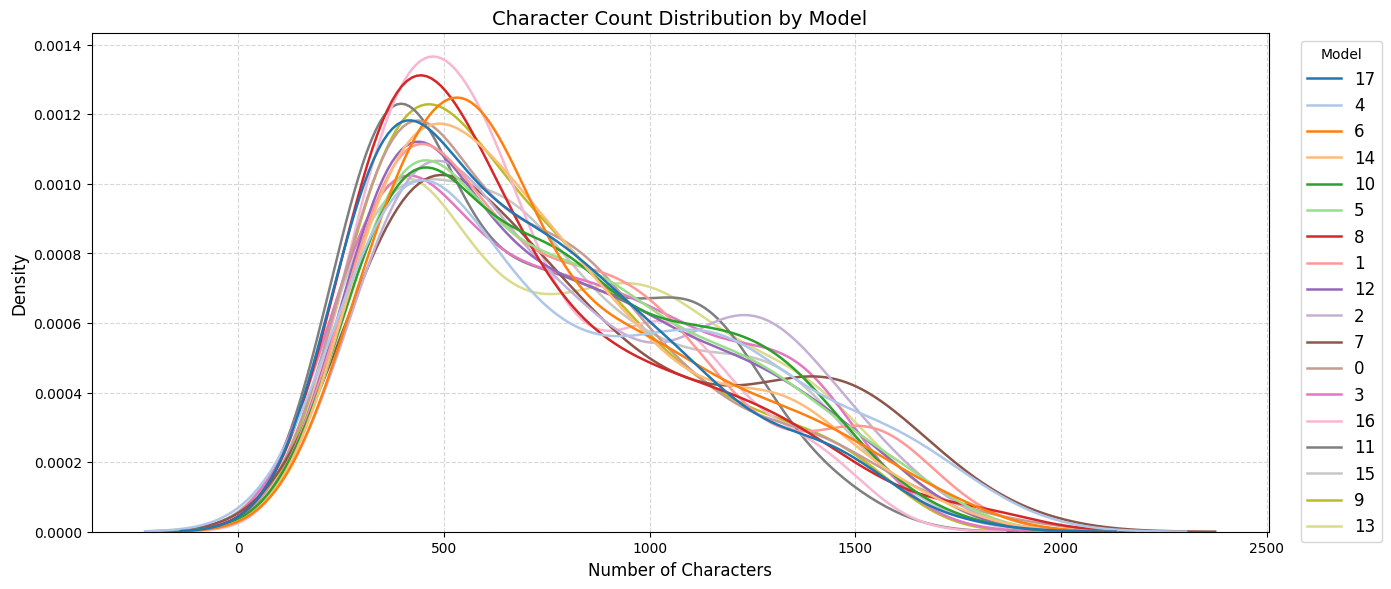

In [78]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 6))

# 1. Ensure 'model' is treated as a string/categorical so Seaborn creates discrete legend items
df_plot = df.copy()
df_plot["model"] = df_plot["model"].astype(str)

# 2. Plot with legend=True
ax = sns.kdeplot(
    data=df_plot,
    x="num_chars",
    hue="model",
    palette="tab20",
    common_norm=False,
    linewidth=1.8,
    legend=True
)

plt.title("Character Count Distribution by Model", fontsize=14)
plt.xlabel("Number of Characters", fontsize=12)
plt.ylabel("Density", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.5)

# 3. Safely move Seaborn's generated legend outside the plot
sns.move_legend(
    ax, 
    loc="upper left", 
    bbox_to_anchor=(1.02, 1), 
    title="Model", 
    frameon=True,
    fontsize=12
)

plt.tight_layout()
plt.show()


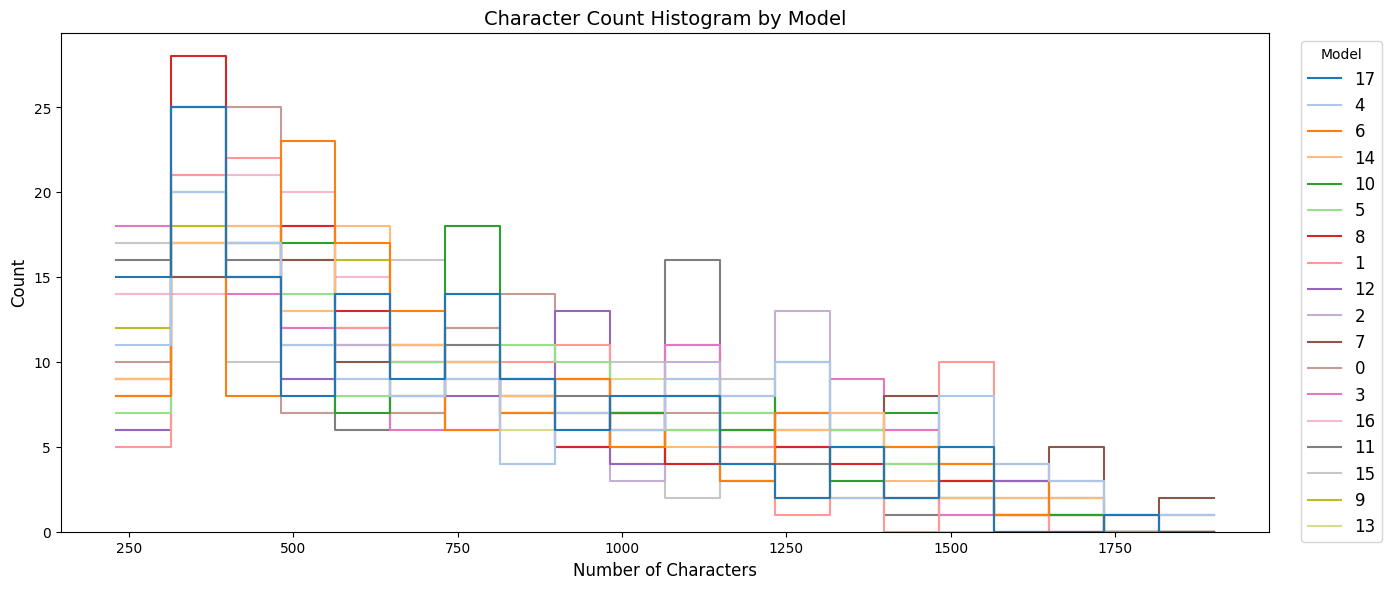

In [79]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 6))

df_plot = df.copy()
df_plot["model"] = df_plot["model"].astype(str)

ax = sns.histplot(
    data=df_plot,
    x="num_chars",
    hue="model",
    palette="tab20",
    element="step",
    fill=False,
    common_norm=False,
    legend=True
)

plt.title("Character Count Histogram by Model", fontsize=14)
plt.xlabel("Number of Characters", fontsize=12)
plt.ylabel("Count", fontsize=12)

# Safely reposition the legend outside
sns.move_legend(
    ax, 
    loc="upper left", 
    bbox_to_anchor=(1.02, 1), 
    title="Model", 
    frameon=True,
    fontsize=12
)

plt.tight_layout()
plt.show()


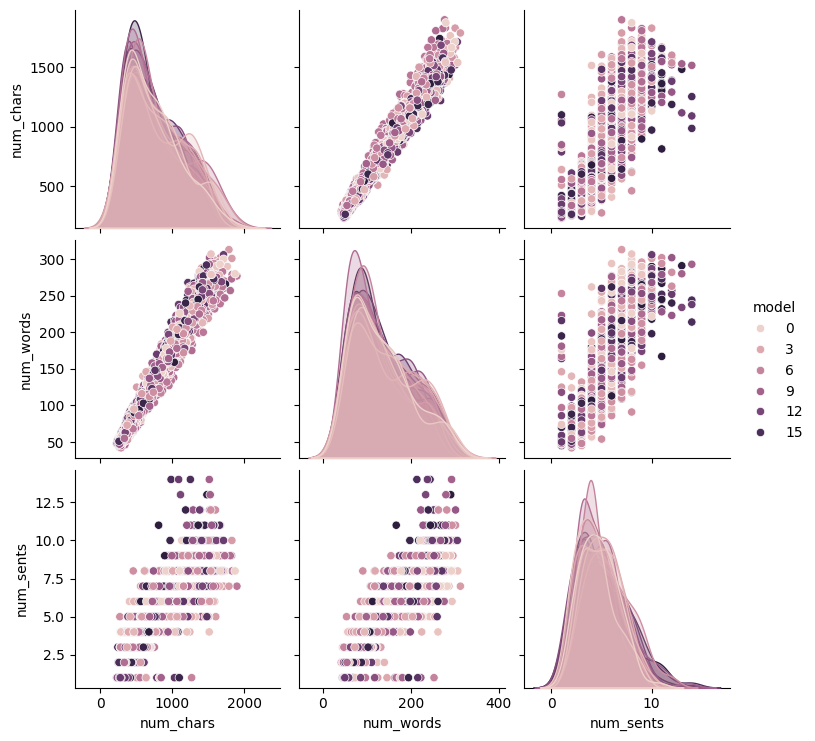

In [80]:
sns.pairplot(df, hue="model")

In [81]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2699 entries, 0 to 2698
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         2699 non-null   object
 1   prompt_id  2699 non-null   object
 2   text       2699 non-null   object
 3   model      2699 non-null   int64 
 4   num_chars  2699 non-null   int64 
 5   num_words  2699 non-null   int64 
 6   num_sents  2699 non-null   int64 
dtypes: int64(4), object(3)
memory usage: 147.7+ KB


<Axes: >

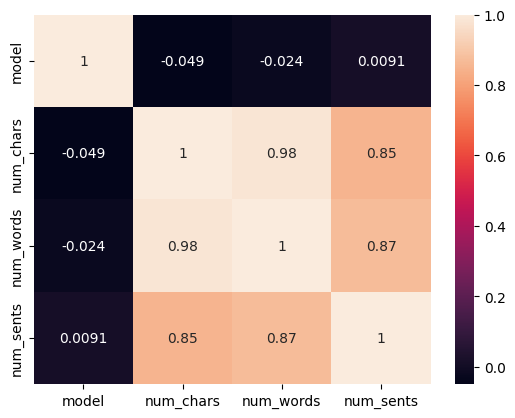

In [82]:
sns.heatmap(df[["model", "num_chars", "num_words", "num_sents"]].corr(), annot=True)

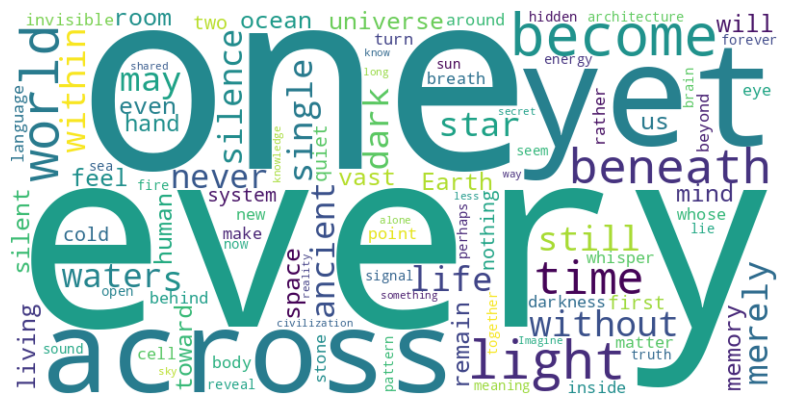

In [83]:
from wordcloud import WordCloud
wordcloud = WordCloud(
    width=800, 
    height=400, 
    background_color='white', 
    colormap='viridis',
    max_words=100
).generate(df["text"].str.cat(sep=" "))

# 5. Display the visual output using Matplotlib
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')  # Hide the x and y axis lines
plt.show()


### Model Training

In [84]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import numpy as np
cv = CountVectorizer()
tfidf = TfidfVectorizer(max_features=3000)


In [85]:
df.head()

,id,prompt_id,text,model,num_chars,num_words,num_sents
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",17,1143,222,8
1,0041ac86ee93,p073,Data science communities matter because they a...,4,518,74,4
2,005a19083eae,p120,"In the final twilight of time, the last embers...",6,474,89,4
3,009319596f10,p073,Data science communities matter because they t...,14,1724,263,9
4,00d3e8c92596,p097,"Deep inside each ear, three tiny loops of bone...",10,541,114,4


In [86]:
df[["num_chars", "num_words", "num_sents"]]

,num_chars,num_words,num_sents
0,1143,222,8
1,518,74,4
2,474,89,4
3,1724,263,9
4,541,114,4
...,...,...,...
2694,1066,178,6
2695,536,86,4
2696,468,95,4
2697,688,99,5


In [87]:
from sklearn.model_selection import train_test_split
df_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
print(df_train.shape, df_test.shape)

(2159, 7) (540, 7)


In [88]:
y_train = df_train["model"].values
y_test = df_test["model"].values

print(y_train.shape, y_test.shape)

(2159,) (540,)


In [89]:
cv = CountVectorizer()
X_train_text = cv.fit_transform(df_train["text"]).toarray()
X_train_num = df_train[["num_chars", "num_words", "num_sents"]].values

X_train = np.hstack((X_train_text, X_train_num))
X_train.shape

(2159, 16352)

In [90]:
X_test_text = cv.transform(df_test["text"]).toarray()
X_test_num = df_test[["num_chars", "num_words", "num_sents"]].values
X_test = np.hstack((X_test_text, X_test_num))
X_test.shape

(540, 16352)

In [91]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, recall_score, confusion_matrix

# Initialize and fit XGBoost
xgb = XGBClassifier(
    objective="multi:softprob",      # Multiclass classification
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    tree_method="hist",              # Fast histogram algorithm
    n_jobs=-1
)

xgb.fit(X_train, y_train)
y_pred = xgb.predict(X_test)

print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.4f}")
print(f"Recall Score: {recall_score(y_test, y_pred, average='macro'):.4f}")
# print(f"Confusion Matrix:\n{confusion_matrix(y_test, y_pred)}")


Accuracy Score: 0.1519
Recall Score: 0.1534


In [92]:
test = pd.read_csv(r"C:\Users\ps302\OneDrive\Desktop\Name_that_LLM\data\test.csv")
test.head()

#  preprocessing
test["num_chars"] = test["text"].apply(len)
test["num_sents"] = test["text"].apply(lambda x: len(sent_tokenize(x)))
test["num_words"] = test["text"].apply(lambda x: len(word_tokenize(x)))
test.head()
X_test = cv.transform(test["text"]).toarray()
X_test = np.hstack((X_test, test[["num_chars", "num_words", "num_sents"]]))
X_test.shape

# Model prediction
y_pred = xgb.predict(X_test)
predictions = le.inverse_transform(y_pred)
predictions


array(['gemini-3.6-flash', 'claude-opus-4-6', 'glm-5.3-flash'],
      dtype=object)

In [93]:
y_pred
print(le.inverse_transform(y_pred))

# or
# for target in y_pred:
#     for key, val in mapping.items():
#         if val==target:
#             predictions.append(key)
# predictions

['gemini-3.6-flash' 'claude-opus-4-6' 'glm-5.3-flash']


In [94]:
len(predictions)

3

In [95]:
# Submission file 
submission = pd.DataFrame({
    "id": test["id"],
    "model": predictions
})

submission.to_parquet("submission.parquet", index=False)
print(f"Saved submission.parquet with {len(submission)} rows.")
submission.head(10)

Saved submission.parquet with 3 rows.


,id,model
0,00353fb1c541,gemini-3.6-flash
1,005f5a9a6139,claude-opus-4-6
2,0062a53d5487,glm-5.3-flash


In [96]:
import os
import pandas as pd
import numpy as np
from pathlib import Path
import nltk
nltk.download("punkt")
from nltk.tokenize import word_tokenize, sent_tokenize

data_folder = Path("data/train.csv")
data_path = os.path.join(os.getcwd(), data_folder)

print(data_path)

# # submission data format
# df = pd.read_parquet(data_path)
# df.head()

df = pd.read_csv(data_path)
df.head()

c:\Users\ps302\OneDrive\Desktop\Name_that_LLM\data\train.csv


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\ps302\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\ps302\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


,id,prompt_id,text,model
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",qwen3.8-max
1,0041ac86ee93,p073,Data science communities matter because they a...,claude-sonnet-5
2,005a19083eae,p120,"In the final twilight of time, the last embers...",gemini-3.6-flash
3,009319596f10,p073,Data science communities matter because they t...,gpt-5.6-terra
4,00d3e8c92596,p097,"Deep inside each ear, three tiny loops of bone...",glm-5.3-flash


In [109]:
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, recall_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer



# 1. Train-test split (WITHOUT stratify to match your non-pipeline split)
df_train, df_test = train_test_split(df, test_size=0.2, random_state=42)

X_train = df_train[["text"]]
y_train = df_train["model"]
X_test = df_test[["text"]]
y_test = df_test["model"]

# 2. Label encode y
le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_test = le.transform(y_test)

# text_feature (custom fucntion)
def text_features(X):
    X = np.asarray(X).ravel()

    return np.array([
        [ len(txt), len(word_tokenize(txt)), len(sent_tokenize(txt)) ] for txt in X
    ])

# 4. Combine both feature extractors into ONE ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ("cv", CountVectorizer(), "text"),
        ("num_features", FunctionTransformer(text_features, validate=False), "text")
    ]
)

# 5. Initialize and fit XGBoost
xgb = XGBClassifier(
    objective="multi:softprob",      # Multiclass classification
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    tree_method="hist",              # Fast histogram algorithm
    n_jobs=-1
)

# 7. Pipeline
pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("to_dense", FunctionTransformer(lambda x: x.toarray(), accept_sparse=True)),
    ("classifier", xgb),
])

pipeline

,steps,"[('preprocessor', ...), ('to_dense', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cv', ...), ('num_features', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [110]:
# pipeline.named_steps
pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.4f}")
print(f"Recall Score: {recall_score(y_test, y_pred, average='macro'):.4f}")

Accuracy Score: 0.1519
Recall Score: 0.1534


In [111]:
test_df = pd.read_csv(r"C:\Users\ps302\OneDrive\Desktop\Name_that_LLM\data\test.csv")
test_df.head()

yt_pred = pipeline.predict(test_df[["text"]])
print(yt_pred)
print(le.inverse_transform(yt_pred)) 

[ 6  1 10]
['gemini-3.6-flash' 'claude-opus-4-6' 'glm-5.3-flash']


In [100]:
# from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
# from sklearn.metrics import accuracy_score, confusion_matrix, recall_score

# gnb = GaussianNB()
# gnb.fit(X_train, y_train)
# y_pred = gnb.predict(X_test)

# print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.4f}")
# print(f"Recall Score: {recall_score(y_test, y_pred,  average='macro'):.4f}")
# # print(f"Confusion Metrics: {confusion_matrix(y_test, y_pred)}")

In [101]:
# from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
# from sklearn.metrics import accuracy_score, confusion_matrix, recall_score

# mnb = MultinomialNB()
# mnb.fit(X_train, y_train)
# y_pred = mnb.predict(X_test)

# print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.4f}")
# print(f"Recall Score: {recall_score(y_test, y_pred,  average='macro'):.4f}")
# # print(f"Confusion Metrics: {confusion_matrix(y_test, y_pred)}")

In [102]:
# from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
# from sklearn.metrics import accuracy_score, confusion_matrix, recall_score

# bnb = BernoulliNB()
# bnb.fit(X_train, y_train)
# y_pred = bnb.predict(X_test)

# print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.4f}")
# print(f"Recall Score: {recall_score(y_test, y_pred,  average='macro'):.4f}")
# # print(f"Confusion Metrics: \n {confusion_matrix(y_test, y_pred)}")

In [103]:
# from sklearn.svm import SVC
# from sklearn.metrics import accuracy_score, recall_score, confusion_matrix

# # 'linear' kernel is usually best and fastest for text/NLP features (TF-IDF, Bag of Words)
# # For non-linear, use kernel='rbf' (default)
# svm = SVC(kernel="linear", random_state=42)
# svm.fit(X_train, y_train)
# y_pred = svm.predict(X_test)

# print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.4f}")
# print(f"Recall Score: {recall_score(y_test, y_pred, average='macro'):.4f}")
# # print(f"Confusion Matrix:\n{confusion_matrix(y_test, y_pred)}")


In [104]:
# from sklearn.svm import SVC
# from sklearn.metrics import accuracy_score, recall_score
# from tqdm import tqdm
# import time

# svm = SVC(kernel="linear", random_state=42)

# # Use tqdm as a simple context manager to show an active progress spinner/timer
# with tqdm(total=1, desc="Training Linear SVM Classifier") as pbar:
#     svm.fit(X_train, y_train)
#     pbar.update(1)

# y_pred = svm.predict(X_test)

# print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.4f}")
# print(f"Recall Score: {recall_score(y_test, y_pred, average='macro'):.4f}")


In [105]:
# from lightgbm import LGBMClassifier
# from sklearn.metrics import accuracy_score, recall_score, confusion_matrix

# lgb = LGBMClassifier(
#     objective="multiclass",
#     n_estimators=100,
#     learning_rate=0.08,
#     num_leaves=31,
#     random_state=42,
#     n_jobs=-1,
#     verbose=-1  # Suppress training warnings/info
# )

# lgb.fit(X_train, y_train)
# y_pred = lgb.predict(X_test)

# print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.4f}")
# print(f"Recall Score: {recall_score(y_test, y_pred, average='macro'):.4f}")
# # print(f"Confusion Matrix:\n{confusion_matrix(y_test, y_pred)}")


In [106]:
# import pandas as pd
# df = pd.read_parquet(r"C:\Users\ps302\OneDrive\Desktop\Name_that_LLM\data\sample_submission.parquet")
# df.head()

In [107]:
# test = pd.read_csv(r"C:\Users\ps302\OneDrive\Desktop\Name_that_LLM\data\test.csv")
# test.head()

In [108]:
# len(test)